# Adversarial Examples against an MNIST CNN
**CYSE 635 — Module 03 Lab** · Erfan Basiri · code for `CYSE635_Module03_Report.pdf`

The target is **DigitNet**, the residual CNN I built in Module 02 (99.70 % clean test accuracy),
loaded unchanged from its checkpoint. The notebook implements and evaluates
random-noise, FGSM, MI-FGSM, PGD (untargeted and targeted) and two black-box attacks
(transfer and the query-based SimBA). It then visualizes what the attacks do to the inputs and
to the network's internal features, and tests two groups of defenses: adversarial training and
input preprocessing.

Everything runs on the GPU. Slow steps (adversarial training) are cached in `checkpoints/`,
and every number used in the report goes to `results/` (CSV + `summary.json`).

In [1]:
# ---------------------------------------------------------------------------
# 0. Imports
# ---------------------------------------------------------------------------
import json, math, platform, random, sys, time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display

In [2]:
# ---------------------------------------------------------------------------
# 0.1 Global settings & reproducibility
# ---------------------------------------------------------------------------
PROJECT_DIR = Path.cwd()                      # the folder that contains this notebook
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"         # tables (CSV) and summary.json
RUNS_DIR = RESULTS_DIR / "runs"               # one JSON record per training run
CKPT_DIR = PROJECT_DIR / "checkpoints"        # weights (module02/ holds the Module 02 models)
FIG_DIR = PROJECT_DIR / "figures"
for _d in (DATA_DIR, RESULTS_DIR, RUNS_DIR, CKPT_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "this notebook is meant to run on the GPU"
torch.backends.cudnn.benchmark = True         # fastest conv kernels for our fixed input size
torch.backends.cuda.matmul.allow_tf32 = True  # TensorFloat-32 matmuls/convs on Ampere+ GPUs
torch.backends.cudnn.allow_tf32 = True


def seed_everything(seed: int) -> None:
    """Seed every random number generator we use (Python, NumPy, PyTorch CPU + CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [3]:
# ---------------------------------------------------------------------------
# 0.2 Data (same split as Module 02, kept resident on the GPU)
# ---------------------------------------------------------------------------
VAL_SIZE = 5_000        # held-out validation images carved from the 60k training set
SPLIT_SEED = 42         # identical split to Module 02, so the loaded models never saw val/test
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081

_DATA = None


def load_data(device=DEVICE):
    """MNIST as float32 tensors in [0, 1] with shape (N, 1, 28, 28), already on the GPU.

    All attacks work in this pixel space: a perturbation of eps = 0.1 means each pixel may
    change by at most 0.1 of the full black-to-white range (about 25 of 255 gray levels).
    Standardization happens inside the models, so the attacker never has to know about it.
    """
    global _DATA
    if _DATA is not None:
        return _DATA
    from sklearn.model_selection import train_test_split

    train = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True)
    test = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True)
    x_all = train.data.float().div_(255.0).unsqueeze(1)
    y_all = train.targets.clone()
    idx_tr, idx_val = train_test_split(
        np.arange(len(y_all)), test_size=VAL_SIZE, stratify=y_all.numpy(), random_state=SPLIT_SEED)
    _DATA = {
        "x_train": x_all[idx_tr].to(device), "y_train": y_all[idx_tr].to(device),
        "x_val": x_all[idx_val].to(device), "y_val": y_all[idx_val].to(device),
        "x_test": test.data.float().div_(255.0).unsqueeze(1).to(device),
        "y_test": test.targets.clone().to(device),
    }
    return _DATA


def iterate_minibatches(x, y, batch_size, shuffle=True):
    """Minimal GPU 'DataLoader' over GPU-resident tensors (fresh permutation every epoch)."""
    n = x.size(0)
    order = torch.randperm(n, device=x.device) if shuffle else torch.arange(n, device=x.device)
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size]
        yield x[idx], y[idx]

In [4]:
# ---------------------------------------------------------------------------
# 0.3 Models (DigitNet + SimpleCNN copied from Module 02, plus the instructor's DNN)
# ---------------------------------------------------------------------------
class Standardize(nn.Module):
    """First layer of the CNNs: (x - mean) / std. Inside the model, so attacks see [0, 1] pixels."""

    def __init__(self, mean=MNIST_MEAN, std=MNIST_STD):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, 1, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 1, 1, 1))

    def forward(self, x):
        return (x - self.mean) / self.std


class SqueezeExcite(nn.Module):
    """Squeeze-and-Excitation channel attention (Hu et al., CVPR 2018)."""

    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.fc1 = nn.Linear(channels, hidden)
        self.fc2 = nn.Linear(hidden, channels)

    def forward(self, x):
        s = x.mean(dim=(2, 3))                              # (N, C) squeeze
        g = torch.sigmoid(self.fc2(F.relu(self.fc1(s))))    # (N, C) excitation gate
        return x * g[:, :, None, None]


class ResidualSEBlock(nn.Module):
    """Residual block:  conv3x3-BN-ReLU -> conv3x3-BN -> SE -> (+ shortcut) -> ReLU."""

    def __init__(self, cin, cout):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.se = SqueezeExcite(cout)
        if cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.se(self.bn2(self.conv2(out)))
        out = out + self.shortcut(x)
        return F.relu(out)


class DigitNet(nn.Module):
    """Module 02 main model: stem conv5x5 -> 3 residual SE blocks -> GAP -> 2 FC layers.
    7 convolutional layers (+2 1x1 shortcut projections) and 2 fully connected layers."""

    def __init__(self, dropout=0.3, widths=(32, 64, 128), hidden=128, n_classes=10):
        super().__init__()
        w1, w2, w3 = widths
        self.standardize = Standardize()
        self.stem = nn.Sequential(nn.Conv2d(1, w1, 5, padding=2, bias=False),
                                  nn.BatchNorm2d(w1), nn.ReLU(inplace=True))
        self.block1 = ResidualSEBlock(w1, w1)             # 32 ch, 28x28
        self.pool1 = nn.MaxPool2d(2)
        self.block2 = ResidualSEBlock(w1, w2)             # 64 ch, 14x14
        self.pool2 = nn.MaxPool2d(2)
        self.block3 = ResidualSEBlock(w2, w3)             # 128 ch, 7x7
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(w3, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(hidden, n_classes))

    def forward(self, x, return_maps=False):
        maps = {}                                         # stage outputs, for feature-map analysis
        x = self.standardize(x)
        x = maps["stem"] = self.stem(x)
        x = maps["block1"] = self.block1(x)
        x = maps["block2"] = self.block2(self.pool1(x))
        x = maps["block3"] = self.block3(self.pool2(x))
        feat = maps["features"] = self.gap(x).flatten(1)  # 128-d penultimate representation
        logits = self.head(feat)
        return (logits, maps) if return_maps else logits


class SimpleCNN(nn.Module):
    """Module 02 baseline (LeNet-style): conv5x5(32)-pool -> conv5x5(64)-pool -> FC 3136->128 -> FC 128->10."""

    def __init__(self, dropout=0.5, n_classes=10):
        super().__init__()
        self.standardize = Standardize()
        self.conv1 = nn.Conv2d(1, 32, 5, padding=2)
        self.conv2 = nn.Conv2d(32, 64, 5, padding=2)
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(64 * 7 * 7, 128), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(128, n_classes))

    def forward(self, x, return_maps=False):
        maps = {}
        x = self.standardize(x)
        x = maps["conv1"] = F.relu(self.conv1(x))
        x = maps["conv2"] = F.relu(self.conv2(F.max_pool2d(x, 2)))
        logits = self.head(F.max_pool2d(x, 2))
        return (logits, maps) if return_maps else logits


class TemplateDNN(nn.Module):
    """The instructor's 5-layer fully connected network (784-512-256-128-64-10), kept as a
    reference point so our numbers can be compared with the lab template."""

    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(), nn.Linear(28 * 28, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

    def forward(self, x):
        return self.layers(x)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def freeze(model):
    """Eval mode + no parameter gradients: attacks only need gradients w.r.t. the input."""
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


def load_module02(name, ctor):
    """Load a Module 02 checkpoint (checkpoints/module02/<name>.pt) into a fresh model."""
    model = ctor().to(DEVICE)
    model.load_state_dict(torch.load(CKPT_DIR / "module02" / f"{name}.pt", map_location=DEVICE))
    return freeze(model)

In [5]:
# ---------------------------------------------------------------------------
# 0.4 Evaluation helpers
# ---------------------------------------------------------------------------
@torch.no_grad()
def predict_logits(model, x, batch_size=5000):
    model.eval()
    return torch.cat([model(x[i:i + batch_size]).float() for i in range(0, len(x), batch_size)])


def accuracy(model, x, y):
    return (predict_logits(model, x).argmax(1) == y).float().mean().item()


def _gauss_kernel(size=7, sigma=1.5, device=DEVICE):
    ax = torch.arange(size, device=device, dtype=torch.float32) - (size - 1) / 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2))
    k = torch.outer(g, g)
    return (k / k.sum()).view(1, 1, size, size)


@torch.no_grad()
def ssim(x, y, C1=0.01 ** 2, C2=0.03 ** 2):
    """Structural similarity (Wang et al., 2004) per image, Gaussian 7x7 window (sigma 1.5).
    1 = identical; a common perceptibility measure that is closer to human judgement than L2."""
    k = _gauss_kernel()
    mu_x, mu_y = F.conv2d(x, k), F.conv2d(y, k)
    sxx = F.conv2d(x * x, k) - mu_x ** 2
    syy = F.conv2d(y * y, k) - mu_y ** 2
    sxy = F.conv2d(x * y, k) - mu_x * mu_y
    m = ((2 * mu_x * mu_y + C1) * (2 * sxy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sxx + syy + C2))
    return m.mean(dim=(1, 2, 3))


@torch.no_grad()
def attack_metrics(model, x, x_adv, y, target=None):
    """Accuracy / success / confidence / perceptibility of one batch of adversarial examples.

    success rate: among images the model classified correctly *before* the attack, the
    fraction that are misclassified afterwards (or, for targeted attacks, hit the target).
    """
    clean_pred = predict_logits(model, x).argmax(1)
    probs = F.softmax(predict_logits(model, x_adv), 1)
    conf, pred = probs.max(1)
    ok = clean_pred == y
    hit = (pred == target) if target is not None else (pred != y)
    d = (x_adv - x).flatten(1)
    return {
        "clean_acc": ok.float().mean().item(),
        "adv_acc": (pred == y).float().mean().item(),
        "success_rate": hit[ok].float().mean().item(),
        "adv_conf": conf[hit & ok].mean().item() if (hit & ok).any() else float("nan"),
        "linf": d.abs().max(1).values.mean().item(),
        "l2": d.norm(dim=1).mean().item(),
        "l0_frac": (d.abs() > 1e-6).float().mean().item(),
        "ssim": ssim(x, x_adv).mean().item(),
        "psnr": (10 * torch.log10(1 / (d ** 2).mean(1).clamp_min(1e-12))).mean().item(),
    }

In [6]:
# ---------------------------------------------------------------------------
# 0.5 Attacks
# ---------------------------------------------------------------------------
# All attacks: L_inf threat model in [0, 1] pixel space, white-box unless stated otherwise.
# `eps` may be a float or a tensor with one value per image (used by the minimal-eps search).

def _eps(eps, x):
    """Broadcast a scalar or per-image eps to shape (N, 1, 1, 1)."""
    return torch.as_tensor(eps, dtype=x.dtype, device=x.device).reshape(-1, 1, 1, 1).expand(len(x), 1, 1, 1)


def input_grad(model, x, y):
    """Gradient of the summed cross-entropy loss w.r.t. the input (one forward + backward pass).
    reduction='sum' keeps every image's gradient independent of the batch size."""
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        logits = model(x)
        loss = F.cross_entropy(logits, y, reduction="sum")
        (g,) = torch.autograd.grad(loss, x)
    return g, logits.detach()


def project(x_adv, x, eps):
    """Projection onto the allowed set: the L_inf ball of radius eps around x, intersected with [0, 1]."""
    return torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)


def noise_attack(model, x, y, eps, kind="sign"):
    """Random-noise baseline. 'sign': +-eps on every pixel (the template's attack; same L_inf and
    L2 size as FGSM). 'gauss': N(0, eps^2) noise. Ignores the model: it is a black-box baseline."""
    e = _eps(eps, x)
    noise = torch.randn_like(x)
    delta = e * noise.sign() if kind == "sign" else e * noise
    return (x + delta).clamp(0, 1)


def fgsm(model, x, y, eps, targeted=False):
    """Fast Gradient Sign Method (Goodfellow et al., 2015): x' = clip(x + eps * sign(grad_x J))."""
    g, _ = input_grad(model, x, y)
    step = _eps(eps, x) * g.sign()
    return (x - step if targeted else x + step).clamp(0, 1).detach()


def pgd(model, x, y, eps, alpha=None, steps=40, random_start=True, restarts=1, targeted=False):
    """Projected Gradient Descent (Madry et al., 2018).

    x_{t+1} = Proj_eps( x_t + alpha * sign(grad_x J(x_t, y)) ), starting from a random point in
    the eps-ball. Default step size alpha = 2.5 * eps / steps, so the iterate can travel from one
    side of the ball to the other. With `restarts` > 1 the attack is repeated from new random
    starts and, per image, the first successful (else the highest-loss) result is kept.
    For a targeted attack `y` is the target class and the loss is *decreased* instead.
    """
    e = _eps(eps, x)
    a = 2.5 * e / steps if alpha is None else _eps(alpha, x)
    best, done = x.clone(), torch.zeros(len(x), dtype=torch.bool, device=x.device)
    best_obj = torch.full((len(x),), -float("inf"), device=x.device)
    for _ in range(restarts):
        x_adv = project(x + (torch.rand_like(x) * 2 - 1) * e, x, e) if random_start else x.clone()
        for _ in range(steps):
            g, _ = input_grad(model, x_adv, y)
            x_adv = project(x_adv - a * g.sign() if targeted else x_adv + a * g.sign(), x, e)
        with torch.no_grad():
            logits = model(x_adv)
            ce = F.cross_entropy(logits, y, reduction="none")
            succ = (logits.argmax(1) == y) if targeted else (logits.argmax(1) != y)
            obj = -ce if targeted else ce
            better = (succ & ~done) | ((succ == done) & (obj > best_obj))
            best[better], best_obj[better] = x_adv[better], obj[better]
            done |= succ
    return best.detach()


def mifgsm(model, x, y, eps, steps=10, mu=1.0):
    """Momentum Iterative FGSM (Dong et al., CVPR 2018). Accumulating the L1-normalised gradient
    with momentum stabilises the update direction; known to transfer better to unseen models."""
    e = _eps(eps, x)
    a = e / steps
    x_adv, g_acc = x.clone(), torch.zeros_like(x)
    for _ in range(steps):
        g, _ = input_grad(model, x_adv, y)
        g_acc = mu * g_acc + g / g.abs().sum(dim=(1, 2, 3), keepdim=True).clamp_min(1e-12)
        x_adv = project(x_adv + a * g_acc.sign(), x, e)
    return x_adv.detach()


@torch.no_grad()
def simba(model, x, y, eps, max_iters=784):
    """SimBA (Guo et al., ICML 2019), pixel basis, L_inf version: a *score-based black-box* attack.

    The attacker only sees output probabilities. In a random pixel order it tries setting one
    pixel's perturbation to +eps, then -eps, and keeps the change if the probability of the true
    class drops. Stops per image once the image is misclassified.
    Returns (x_adv, queries_until_success) with inf for images that were never fooled.
    """
    model.eval()
    n, d = len(x), x[0].numel()
    xf = x.flatten(1)
    delta = torch.zeros_like(xf)
    probs = F.softmax(model(x), 1)
    p = probs.gather(1, y[:, None]).squeeze(1)
    queries = torch.ones(n, device=x.device)
    fooled_at = torch.where(probs.argmax(1) != y, torch.ones(n, device=x.device),
                            torch.full((n,), float("inf"), device=x.device))
    perm = torch.argsort(torch.rand(n, d, device=x.device), dim=1)
    for t in range(min(max_iters, d)):
        active = torch.isinf(fooled_at).nonzero().squeeze(1)
        if len(active) == 0:
            break
        idx = perm[active, t]
        for sgn in (1.0, -1.0):
            cand = delta[active].clone()
            cand[torch.arange(len(active)), idx] = sgn * eps
            pr = F.softmax(model((xf[active] + cand).clamp(0, 1).view(-1, *x.shape[1:])), 1)
            queries[active] += 1
            p_new = pr.gather(1, y[active, None]).squeeze(1)
            better = p_new < p[active]
            acc_idx = active[better]
            delta[acc_idx] = cand[better]
            p[acc_idx] = p_new[better]
            newly = acc_idx[(pr[better].argmax(1) != y[acc_idx])]
            fooled_at[newly] = queries[newly]
            # images that improved with +eps do not try -eps in this round
            keep = ~better
            active, idx = active[keep], idx[keep]
            if len(active) == 0:
                break
    return (xf + delta).clamp(0, 1).view_as(x), fooled_at


def run_attack(model, attack, x, y, batch_size=2500, **kw):
    """Apply `attack(model, x, y, **kw)` batch by batch (keeps GPU memory bounded)."""
    return torch.cat([attack(model, x[i:i + batch_size], y[i:i + batch_size], **kw)
                      for i in range(0, len(x), batch_size)])

In [7]:
# ---------------------------------------------------------------------------
# 0.6 Defenses: input transformations (+ BPDA for adaptive attacks) and adversarial training
# ---------------------------------------------------------------------------
def bit_depth(x, bits=1):
    """Bit-depth reduction / feature squeezing: keep only 2**bits gray levels (1 bit = binarize)."""
    levels = 2 ** bits - 1
    return torch.round(x * levels) / levels


def median_filter(x, k=3):
    """k x k median smoothing (reflect padding)."""
    p = k // 2
    patches = F.unfold(F.pad(x, (p, p, p, p), mode="reflect"), k)       # (N, k*k, H*W)
    return patches.median(dim=1).values.view_as(x)


def gaussian_blur(x, sigma=1.0, size=5):
    return F.conv2d(F.pad(x, (size // 2,) * 4, mode="reflect"), _gauss_kernel(size, sigma, x.device))


class Preprocessed(nn.Module):
    """model(transform(x)). With bpda=True the backward pass treats the transform as the identity
    (Backward Pass Differentiable Approximation, Athalye et al., ICML 2018): the forward pass is
    exactly the defense, but an attacker still gets useful gradients through it."""

    def __init__(self, model, transform, bpda=False):
        super().__init__()
        self.model, self.transform, self.bpda = model, transform, bpda

    def forward(self, x):
        t = self.transform(x)
        if self.bpda:
            t = x + (t - x).detach()      # value = transform(x), gradient = identity
        return self.model(t)


@dataclass(frozen=True)
class ATConfig:
    """One adversarial-training run (DigitNet architecture, trained from scratch)."""
    method: str = "pgd"        # 'pgd' (Madry et al.) or 'fgsm_rs' (FGSM + random start, Wong et al.)
    eps: float = 0.3           # training budget (the standard MNIST eps)
    steps: int = 10            # PGD steps per training batch (ignored for fgsm_rs)
    epochs: int = 20
    ramp_epochs: int = 5       # eps grows linearly from 0 to its final value over the first epochs
    lr: float = 1e-3           # peak learning rate (one-cycle schedule, AdamW)
    weight_decay: float = 1e-2
    batch_size: int = 128
    seed: int = 0

    @property
    def name(self):
        return f"at_{self.method}_eps{self.eps}_s{self.seed}"


def make_adv_batch(model, xb, yb, eps, cfg):
    """Training-time adversarial examples, crafted in eval mode (BN running stats untouched)."""
    model.eval()
    if cfg.method == "pgd":
        x_adv = pgd(model, xb, yb, eps, steps=cfg.steps)
    else:                                   # FGSM with a random start, step 1.25 * eps
        e = torch.full((len(xb),), eps, device=xb.device).view(-1, 1, 1, 1)
        x0 = project(xb + (torch.rand_like(xb) * 2 - 1) * e, xb, e)
        g, _ = input_grad(model, x0, yb)
        x_adv = project(x0 + 1.25 * e * g.sign(), xb, e)
    model.train()
    return x_adv.detach()


def adversarial_train(cfg: ATConfig, force=False, verbose=True):
    """min_theta max_{||delta||<=eps} CE(f(x + delta), y), with the inner max approximated by
    PGD (or FGSM-RS). The checkpoint with the best *robust* validation accuracy (PGD-20 on
    1,000 validation images at the full eps) is kept. Cached: re-running loads the weights."""
    ckpt, rec_path = CKPT_DIR / f"{cfg.name}.pt", RUNS_DIR / f"{cfg.name}.json"
    if not force and ckpt.exists() and rec_path.exists():
        rec = json.loads(rec_path.read_text())
        if rec["config"] == asdict(cfg):
            model = DigitNet().to(DEVICE)
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
            if verbose:
                print(f"[cache] {cfg.name}: best epoch {rec['best_epoch']}, "
                      f"val clean {100 * rec['best_val_clean']:.2f}%, val PGD {100 * rec['best_val_rob']:.2f}%")
            return freeze(model), rec

    d = load_data()
    seed_everything(cfg.seed)
    model = DigitNet().to(DEVICE)
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": cfg.weight_decay},
                             {"params": no_decay, "weight_decay": 0.0}], lr=cfg.lr)
    n_batches = math.ceil(len(d["y_train"]) / cfg.batch_size)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.lr, total_steps=cfg.epochs * n_batches,
                                                pct_start=0.25)
    xv, yv = d["x_val"][:1000], d["y_val"][:1000]
    hist = {k: [] for k in ["epoch", "eps", "train_adv_loss", "train_adv_acc", "val_clean_acc",
                            "val_fgsm_acc", "val_pgd_acc", "epoch_time"]}
    best = (-1.0, 0, None, 0.0)
    t_start = time.time()
    for epoch in range(1, cfg.epochs + 1):
        t0 = time.time()
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE)
        for i, (xb, yb) in enumerate(iterate_minibatches(d["x_train"], d["y_train"], cfg.batch_size)):
            progress = (epoch - 1 + i / n_batches) / max(cfg.ramp_epochs, 1e-9)
            eps_now = cfg.eps * min(1.0, progress)
            x_adv = make_adv_batch(model, xb, yb, eps_now, cfg)
            logits = model(x_adv)
            loss = F.cross_entropy(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            loss_sum += loss.detach() * len(yb)
            correct += (logits.argmax(1) == yb).sum()
        torch.cuda.synchronize()
        model.eval()
        val_clean = accuracy(model, d["x_val"], d["y_val"])
        val_fgsm = accuracy(model, fgsm(model, xv, yv, cfg.eps), yv)
        val_pgd = accuracy(model, pgd(model, xv, yv, cfg.eps, steps=20), yv)
        n = len(d["y_train"])
        row = [epoch, eps_now, loss_sum.item() / n, correct.item() / n, val_clean, val_fgsm, val_pgd,
               time.time() - t0]
        for k, v in zip(hist, row):
            hist[k].append(v)
        if verbose:
            print(f"{cfg.name} | ep {epoch:02d} | eps {eps_now:.3f} | adv-train {row[2]:.4f}/{100 * row[3]:.2f}% | "
                  f"val clean {100 * val_clean:.2f}% | val FGSM {100 * val_fgsm:.2f}% | "
                  f"val PGD-20 {100 * val_pgd:.2f}% | {row[-1]:.1f}s")
        if epoch >= cfg.ramp_epochs and val_pgd > best[0]:
            best = (val_pgd, epoch, {k: v.detach().clone() for k, v in model.state_dict().items()}, val_clean)
        model.train()
    model.load_state_dict(best[2])
    rec = {"name": cfg.name, "config": asdict(cfg), "history": hist, "best_epoch": best[1],
           "best_val_rob": best[0], "best_val_clean": best[3], "train_time_s": time.time() - t_start}
    torch.save({k: v.cpu() for k, v in model.state_dict().items()}, ckpt)
    rec_path.write_text(json.dumps(rec, indent=1))
    return freeze(model), rec

In [8]:
# ---------------------------------------------------------------------------
# 0.7 Plot styling (same color-blind-safe palette as Module 02) and small utilities
# ---------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
GOOD, BAD = "#008300", "#e34948"


def set_style():
    from cycler import cycler
    plt.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
        "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.labelsize": 9, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
        "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
        "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
        "xtick.labelsize": 8, "ytick.labelsize": 8,
        "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
        "lines.markersize": 4.5, "legend.frameon": False, "legend.fontsize": 8, "text.color": INK,
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "pdf.fonttype": 42,
        "axes.prop_cycle": cycler(color=PALETTE), "image.interpolation": "nearest",
    })


def seq_cmap():
    from matplotlib.colors import LinearSegmentedColormap
    return LinearSegmentedColormap.from_list(
        "seq_blue", ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])


def div_cmap():
    """Diverging blue <-> red with a neutral midpoint, for signed perturbations
    (blue = pixel value decreased, red = increased)."""
    from matplotlib.colors import LinearSegmentedColormap
    return LinearSegmentedColormap.from_list("div_blue_red", ["#2a78d6", "#f0efec", "#e34948"])


def save_fig(fig, name):
    for ext in ("png", "pdf"):
        path = FIG_DIR / f"{name}.{ext}"
        try:
            fig.savefig(path)
        except PermissionError:
            print(f"warning: could not overwrite {path.name} (it is open in another program)")


def show_img(ax, img, cmap="gray_r", title=None, color=INK2, **kw):
    ax.imshow(img.detach().cpu() if torch.is_tensor(img) else img, cmap=cmap, **kw)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    if title is not None:
        ax.set_title(title, loc="center", fontsize=7, fontweight="normal", color=color, pad=2)


def save_table(df, name):
    df.to_csv(RESULTS_DIR / f"{name}.csv")


def df_json(df):
    return json.loads(df.to_json(orient="index"))


set_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
SUMMARY = {}                    # every headline number -> results/summary.json
env = {
    "python": sys.version.split()[0], "pytorch": torch.__version__, "cuda": torch.version.cuda,
    "os": platform.platform(),
}
SUMMARY["environment"] = env
for k, v in env.items():
    print(f"{k:14s}: {v}")

python        : 3.11.14
pytorch       : 2.9.1+cu128
cuda          : 12.8
os            : Windows-10-10.0.26300-SP0


## 1. Model setup
DigitNet (target) and SimpleCNN are the Module 02 checkpoints. A second DigitNet (seed 1) serves
as a surrogate for black-box transfer attacks. The instructor's fully connected `simpleDNN` is
retrained exactly as in the template (Adam, lr 1e-3, batch 256, 10 epochs) as a reference point.

In [9]:
data = load_data()
x_train, y_train = data["x_train"], data["y_train"]
x_val, y_val = data["x_val"], data["y_val"]
x_test, y_test = data["x_test"], data["y_test"]
y_test_np = y_test.cpu().numpy()
print(f"train {tuple(x_train.shape)} | val {tuple(x_val.shape)} | test {tuple(x_test.shape)} | on {x_test.device}")

digitnet = load_module02("main_s0", DigitNet)                     # the target model
digitnet_s1 = load_module02("main_s1", DigitNet)                  # surrogate: same architecture, other seed
simplecnn = load_module02("arch=simple,dropout=0.5,augment=False_s0", lambda: SimpleCNN(0.5))


def train_template_dnn(seed=0, epochs=10, lr=1e-3, batch_size=256):
    """Retrain the template's simpleDNN as the instructor does (cached)."""
    path = CKPT_DIR / f"template_dnn_s{seed}.pt"
    model = TemplateDNN().to(DEVICE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        return freeze(model)
    seed_everything(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(epochs):
        for xb, yb in iterate_minibatches(x_train, y_train, batch_size):
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
    torch.save(model.state_dict(), path)
    return freeze(model)


template_dnn = train_template_dnn()
STD_MODELS = {"DigitNet": digitnet, "SimpleCNN": simplecnn, "TemplateDNN": template_dnn}

rows = []
for name, m in {**STD_MODELS, "DigitNet (seed 1)": digitnet_s1}.items():
    n_conv = sum(isinstance(l, nn.Conv2d) and l.kernel_size[0] > 1 for l in m.modules())
    n_fc = sum(isinstance(l, nn.Linear) for l in (m.head if hasattr(m, "head") else m).modules())
    rows.append({"model": name, "parameters": n_params(m), "conv layers": n_conv, "FC layers": n_fc,
                 "clean test acc": accuracy(m, x_test, y_test)})
models_df = pd.DataFrame(rows).set_index("model")
save_table(models_df, "models")
SUMMARY["models"] = df_json(models_df)
display(models_df)

train (55000, 1, 28, 28) | val (5000, 1, 28, 28) | test (10000, 1, 28, 28) | on cuda:0


,parameters,conv layers,FC layers,clean test acc
model,,,,
DigitNet,330726,7,2,0.9970
SimpleCNN,454922,2,2,0.9951
TemplateDNN,575050,0,5,0.9787
DigitNet (seed 1),330726,7,2,0.9960


## 2. Adversarial example generation: a first look
FGSM and PGD examples on DigitNet, shown side by side and across eps.

In [10]:
EPS_GRID = [0.0, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.25, 0.3]
REPORT_EPS = [0.1, 0.2, 0.3]
seed_everything(0)

ATTACKS = {   # name -> (function, kwargs); every attack has the signature f(model, x, y, eps, ...)
    "Noise (±ε sign)": (noise_attack, {"kind": "sign"}),
    "Noise (Gaussian σ=ε)": (noise_attack, {"kind": "gauss"}),
    "FGSM": (fgsm, {}),
    "MI-FGSM (10 steps)": (mifgsm, {"steps": 10}),
    "PGD-40": (pgd, {"steps": 40}),
}

# wall-clock cost of the attacks on the whole test set (after one warm-up run)
run_attack(digitnet, pgd, x_test[:2500], y_test[:2500], eps=0.1, steps=5)
timing = {}
for aname, fn, kw in [("FGSM", fgsm, {}), ("PGD-40", pgd, {"steps": 40})]:
    torch.cuda.synchronize(); t0 = time.time()
    run_attack(digitnet, fn, x_test, y_test, eps=0.1, **kw)
    torch.cuda.synchronize(); timing[aname] = time.time() - t0
SUMMARY["attack_seconds_10k"] = timing
print({k: f"{v:.2f}s" for k, v in timing.items()})

{'FGSM': '0.10s', 'PGD-40': '3.85s'}


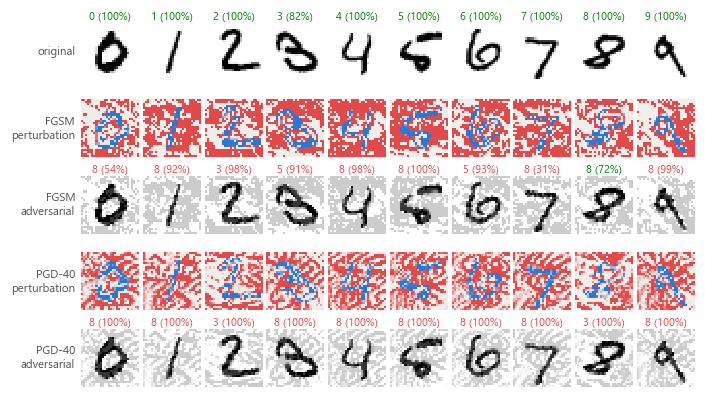

In [11]:
# Figure: side-by-side original / perturbation / adversarial images for FGSM and PGD (eps = 0.2)
EPS_SHOW = 0.2
idx_show = [int(np.flatnonzero(y_test_np == d)[0]) for d in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]
xs, ys = x_test[idx_show], y_test[idx_show]
adv_show = {"FGSM": fgsm(digitnet, xs, ys, EPS_SHOW), "PGD-40": pgd(digitnet, xs, ys, EPS_SHOW, steps=40)}


def pred_title(model, x):
    p = F.softmax(predict_logits(model, x), 1)
    c, k = p.max(1)
    return k.cpu().numpy(), c.cpu().numpy()


fig, axes = plt.subplots(5, 10, figsize=(7.2, 4.3))
k0, c0 = pred_title(digitnet, xs)
row_labels = ["original"]
for j in range(10):
    show_img(axes[0, j], xs[j, 0], title=f"{k0[j]} ({100 * c0[j]:.0f}%)", color=GOOD if k0[j] == ys[j].item() else BAD)
for r, aname in enumerate(adv_show):
    xa = adv_show[aname]
    k, c = pred_title(digitnet, xa)
    for j in range(10):
        show_img(axes[1 + 2 * r, j], (xa - xs)[j, 0], cmap=div_cmap(), vmin=-EPS_SHOW, vmax=EPS_SHOW)
        show_img(axes[2 + 2 * r, j], xa[j, 0], title=f"{k[j]} ({100 * c[j]:.0f}%)",
                 color=GOOD if k[j] == ys[j].item() else BAD)
    row_labels += [f"{aname}\nperturbation", f"{aname}\nadversarial"]
for r, lab in enumerate(row_labels):
    axes[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=7.5, color=INK2)
fig.subplots_adjust(wspace=0.06, hspace=0.32)
save_fig(fig, "fig_side_by_side")
plt.show()

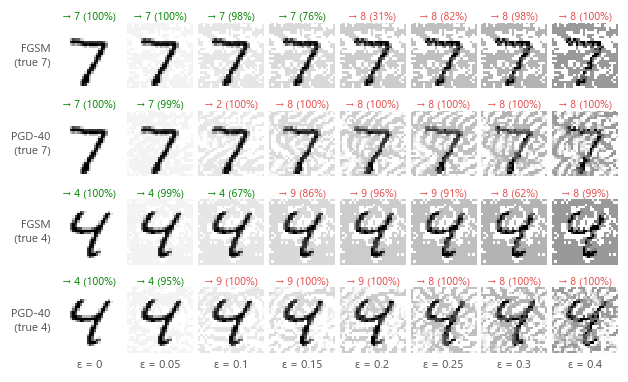

In [12]:
# Figure: one digit attacked with growing eps (FGSM and PGD), to see when it breaks and how visible it is
EPS_STRIP = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4]
i_strip = [int(np.flatnonzero(y_test_np == 7)[0]), int(np.flatnonzero(y_test_np == 4)[1])]
fig, axes = plt.subplots(4, len(EPS_STRIP), figsize=(6.6, 3.9))
r = 0
for i in i_strip:
    xi, yi = x_test[i:i + 1], y_test[i:i + 1]
    for aname, fn in [("FGSM", fgsm), ("PGD-40", lambda m, x, y, e: pgd(m, x, y, e, steps=40))]:
        for c, eps in enumerate(EPS_STRIP):
            xa = xi if eps == 0 else fn(digitnet, xi, yi, eps)
            k, conf = pred_title(digitnet, xa)
            show_img(axes[r, c], xa[0, 0], title=f"→ {k[0]} ({100 * conf[0]:.0f}%)",
                     color=GOOD if k[0] == yi.item() else BAD)
            if r == 3:
                axes[r, c].set_xlabel(f"ε = {eps:g}", fontsize=7.5, color=INK2)
        axes[r, 0].set_ylabel(f"{aname}\n(true {yi.item()})", rotation=0, ha="right", va="center", fontsize=7.5, color=INK2)
        r += 1
fig.subplots_adjust(wspace=0.06, hspace=0.35)
save_fig(fig, "fig_eps_strip")
plt.show()

## 3. Testing and evaluation: clean vs adversarial accuracy
Every attack x every eps x every standard model, on all 10,000 test images.

In [13]:
t0 = time.time()
rows = []
for mname, m in STD_MODELS.items():
    for aname, (fn, kw) in ATTACKS.items():
        for eps in EPS_GRID:
            if eps == 0:
                x_adv = x_test
            else:
                seed_everything(0)
                x_adv = run_attack(m, fn, x_test, y_test, eps=eps, **kw)
            rows.append({"model": mname, "attack": aname, "eps": eps, **attack_metrics(m, x_test, x_adv, y_test)})
sweep = pd.DataFrame(rows)
save_table(sweep, "eps_sweep")
print(f"{len(rows)} evaluations in {time.time() - t0:.0f}s")
acc_tbl = sweep.pivot_table(index=["model", "attack"], columns="eps", values="adv_acc", sort=False)
display((100 * acc_tbl).round(2))
SUMMARY["eps_sweep"] = sweep.to_dict(orient="records")

135 evaluations in 57s


eps                                0.00   0.02   0.05   0.08   0.10   0.15   0.20   0.25   0.30
model       attack                                                                             
DigitNet    Noise (±ε sign)       99.70  99.70  99.56  98.64  95.97  78.26  54.47  25.71  12.22
            Noise (Gaussian σ=ε)  99.70  99.70  99.60  98.96  96.09  80.04  59.90  33.27  16.44
            FGSM                  99.70  98.92  95.04  83.99  71.35  38.14  17.19  11.53  10.86
            MI-FGSM (10 steps)    99.70  98.82  93.05  72.28  50.86  13.06   4.15   1.03   0.17
            PGD-40                99.70  98.70  85.28  35.89  11.96   0.76   0.00   0.00   0.00
SimpleCNN   Noise (±ε sign)       99.51  99.52  99.48  99.43  99.42  99.19  98.92  97.73  92.54
            Noise (Gaussian σ=ε)  99.51  99.51  99.48  99.43  99.41  99.23  98.87  97.65  93.00
            FGSM                  99.51  98.69  96.81  92.91  88.26  70.15  50.46  34.32  21.95
            MI-FGSM (10 steps)    99.51  98.57  96.12  89.25  79.92  44.10  13.64   2.64   0.39
            PGD-40                99.51  98.52  95.37  83.07  65.63  10.57   0.15   0.00   0.00
TemplateDNN Noise (±ε sign)       97.87  97.72  97.17  95.67  94.01  84.90  71.07  59.31  49.40
            Noise (Gaussian σ=ε)  97.87  97.76  97.40  96.47  95.52  90.21  80.86  69.65  60.34
            FGSM                  97.87  89.51  52.71  26.03  17.95   8.92   5.72   3.99   2.98
            MI-FGSM (10 steps)    97.87  89.13  48.30  18.77  10.52   2.91   1.01   0.64   0.45
            PGD-40                97.87  88.60  41.96  10.99   3.64   0.17   0.05   0.02   0.01

In [14]:
# Headline table: DigitNet, clean vs adversarial at the report budgets
head = sweep[(sweep.model == "DigitNet") & (sweep.eps.isin(REPORT_EPS))]
head_tbl = head.pivot_table(index="attack", columns="eps", values=["adv_acc", "success_rate"], sort=False)
display((100 * head_tbl).round(2))

# Template reproduction: the instructor's settings on the instructor's model
seed_everything(0)
tmpl = {
    "FGSM eps=0.08": accuracy(template_dnn, run_attack(template_dnn, fgsm, x_test, y_test, eps=0.08), y_test),
    "noise eps=0.15": accuracy(template_dnn, run_attack(template_dnn, noise_attack, x_test, y_test, eps=0.15), y_test),
    "PGD eps=0.08 (40 steps, alpha=0.004, no random start)": accuracy(
        template_dnn, run_attack(template_dnn, pgd, x_test, y_test, eps=0.08, alpha=0.004, steps=40,
                                 random_start=False), y_test),
}
SUMMARY["template_reproduction"] = tmpl
for k, v in tmpl.items():
    print(f"TemplateDNN {k:55s}: {100 * v:.2f}%")

adv_acc               success_rate                
eps                      0.1    0.2    0.3          0.1     0.2     0.3
attack                                                                 
Noise (±ε sign)        95.97  54.47  12.22         3.81   45.41   87.77
Noise (Gaussian σ=ε)   96.09  59.90  16.44         3.71   39.96   83.54
FGSM                   71.35  17.19  10.86        28.44   82.76   89.12
MI-FGSM (10 steps)     50.86   4.15   0.17        48.99   95.84   99.83
PGD-40                 11.96   0.00   0.00        88.00  100.00  100.00

TemplateDNN FGSM eps=0.08                                          : 26.03%
TemplateDNN noise eps=0.15                                         : 84.90%
TemplateDNN PGD eps=0.08 (40 steps, alpha=0.004, no random start)  : 11.71%


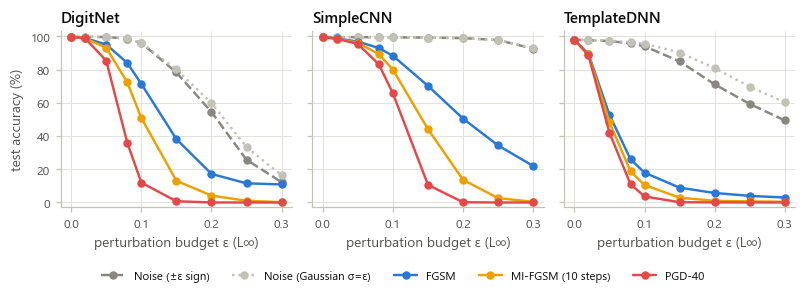

In [15]:
# Figure: accuracy vs eps for every model and attack
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.6), sharey=True)
styles = {"Noise (±ε sign)": dict(color=MUTED, ls="--"), "Noise (Gaussian σ=ε)": dict(color=AXIS, ls=":"),
          "FGSM": dict(color=PALETTE[0]), "MI-FGSM (10 steps)": dict(color=PALETTE[3]),
          "PGD-40": dict(color=PALETTE[7])}
for ax, mname in zip(axes, STD_MODELS):
    sub = sweep[sweep.model == mname]
    for aname, st in styles.items():
        s = sub[sub.attack == aname]
        ax.plot(s.eps, 100 * s.adv_acc, marker="o", label=aname, **st)
    ax.set_title(mname)
    ax.set_xlabel("perturbation budget ε (L∞)")
    ax.set_ylim(-3, 103)
axes[0].set_ylabel("test accuracy (%)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04), fontsize=7.5)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_fig(fig, "fig_robustness_curves")
plt.show()

### 3.1 Is PGD converged? Steps and restarts (sanity check against gradient masking)

In [16]:
xs2, ys2 = x_test[:2000], y_test[:2000]
rows = []
for eps in [0.1, 0.2]:
    for steps in [1, 2, 5, 10, 20, 40, 100, 200]:
        seed_everything(0)
        rows.append({"eps": eps, "steps": steps, "restarts": 1,
                     "acc": accuracy(digitnet, run_attack(digitnet, pgd, xs2, ys2, eps=eps, steps=steps), ys2)})
    seed_everything(0)
    rows.append({"eps": eps, "steps": 100, "restarts": 10,
                 "acc": accuracy(digitnet, run_attack(digitnet, pgd, xs2, ys2, eps=eps, steps=100, restarts=10), ys2)})
steps_df = pd.DataFrame(rows)
save_table(steps_df, "pgd_steps")
SUMMARY["pgd_steps"] = steps_df.to_dict(orient="records")
display(steps_df.pivot_table(index=["steps", "restarts"], columns="eps", values="acc"))

eps                0.1     0.2
steps restarts                
1     1         0.5480  0.0840
2     1         0.3185  0.0645
5     1         0.1490  0.0050
10    1         0.1085  0.0005
20    1         0.0965  0.0005
40    1         0.0895  0.0000
100   1         0.0860  0.0005
      10        0.0660  0.0000
200   1         0.0860  0.0000

## 4. Visualization and analysis
### 4.1 Perturbation magnitude vs perceptibility (the eps trade-off)

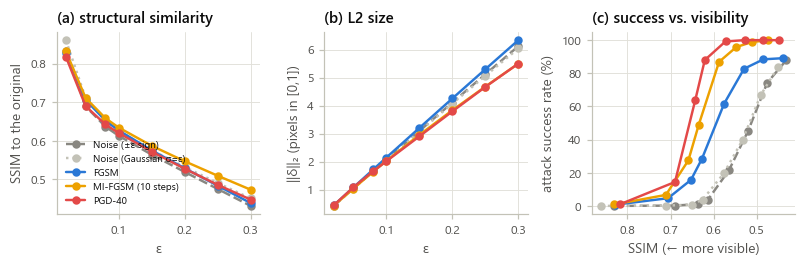

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.5))
sub = sweep[(sweep.model == "DigitNet") & (sweep.eps > 0)]
for aname, st in styles.items():
    s = sub[sub.attack == aname]
    axes[0].plot(s.eps, s.ssim, marker="o", label=aname, **st)
    axes[1].plot(s.eps, s.l2, marker="o", **st)
    axes[2].plot(s.ssim, 100 * s.success_rate, marker="o", **st)
axes[0].set_title("(a) structural similarity"); axes[0].set_xlabel("ε"); axes[0].set_ylabel("SSIM to the original")
axes[1].set_title("(b) L2 size"); axes[1].set_xlabel("ε"); axes[1].set_ylabel("‖δ‖₂ (pixels in [0,1])")
axes[2].set_title("(c) success vs. visibility"); axes[2].set_xlabel("SSIM (← more visible)")
axes[2].set_ylabel("attack success rate (%)"); axes[2].invert_xaxis()
axes[0].legend(fontsize=6.5, loc="lower left")
fig.tight_layout()
save_fig(fig, "fig_perceptibility")
plt.show()

### 4.2 Where do adversarial examples go? Untargeted confusion and targeted attacks

,mean targeted success,hardest pair,hardest success,easiest pair,easiest success
eps,,,,,
0.1,0.5069,6→7,0.00,1→0,1.0
0.2,0.9976,8→0,0.95,0→1,1.0


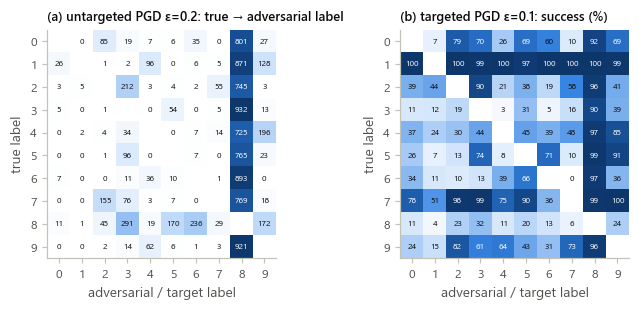

In [18]:
from sklearn.metrics import confusion_matrix
seed_everything(0)
xa = run_attack(digitnet, pgd, x_test, y_test, eps=0.2, steps=40)
pa = predict_logits(digitnet, xa).argmax(1).cpu().numpy()
cm_adv = confusion_matrix(y_test_np, pa, labels=range(10))
save_table(pd.DataFrame(cm_adv), "adv_confusion_pgd0.2")

# targeted PGD: 100 correctly classified test images per digit, pushed to each of the 9 other digits
sel = []
clean_pred = predict_logits(digitnet, x_test).argmax(1).cpu().numpy()
for c in range(10):
    sel += list(np.flatnonzero((y_test_np == c) & (clean_pred == c))[:100])
sel = torch.tensor(sel, device=DEVICE)
xt, yt = x_test[sel], y_test[sel]
tgt_rows = []
targeted_succ = {}
for eps in [0.1, 0.2]:
    M = np.full((10, 10), np.nan)
    for t in range(10):
        mask = yt != t
        tgt = torch.full_like(yt[mask], t)
        seed_everything(0)
        xa_t = pgd(digitnet, xt[mask], tgt, eps, steps=100, targeted=True)
        hit = (predict_logits(digitnet, xa_t).argmax(1) == tgt).cpu().numpy()
        src = yt[mask].cpu().numpy()
        for s in range(10):
            if s != t:
                M[s, t] = hit[src == s].mean()
    targeted_succ[eps] = M
    tgt_rows.append({"eps": eps, "mean targeted success": np.nanmean(M),
                     "hardest pair": "{}→{}".format(*np.unravel_index(np.nanargmin(M), M.shape)),
                     "hardest success": np.nanmin(M),
                     "easiest pair": "{}→{}".format(*np.unravel_index(np.nanargmax(M), M.shape)),
                     "easiest success": np.nanmax(M)})
targeted_df = pd.DataFrame(tgt_rows).set_index("eps")
save_table(targeted_df, "targeted")
for eps, M in targeted_succ.items():
    save_table(pd.DataFrame(M), f"targeted_matrix_eps{eps}")
SUMMARY["targeted"] = df_json(targeted_df)
display(targeted_df)

fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.9))
off = cm_adv.copy().astype(float); np.fill_diagonal(off, np.nan)
for ax, (mat, title, fmt) in zip(axes, [
        (off, "(a) untargeted PGD ε=0.2: true → adversarial label", "{:.0f}"),
        (100 * targeted_succ[0.1], "(b) targeted PGD ε=0.1: success (%)", "{:.0f}")]):
    im = ax.imshow(np.ma.masked_invalid(mat), cmap=seq_cmap())
    for s in range(10):
        for t in range(10):
            if not np.isnan(mat[s, t]):
                v = mat[s, t]
                ax.text(t, s, fmt.format(v), ha="center", va="center", fontsize=5.5,
                        color="white" if v > 0.6 * np.nanmax(mat) else INK)
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
    ax.set_xlabel("adversarial / target label"); ax.set_ylabel("true label")
    ax.set_title(title, fontsize=8.5)
fig.tight_layout()
save_fig(fig, "fig_adv_confusion")
plt.show()

### 4.3 Inside the network: feature maps, perturbation amplification, attention

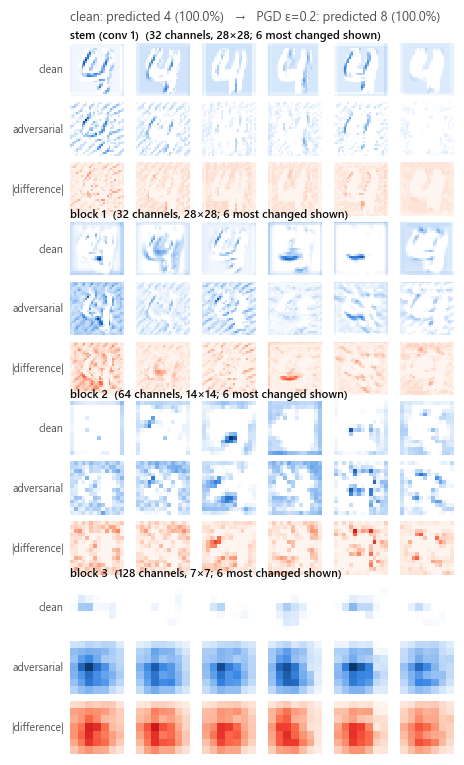

In [19]:
# Figure: feature maps for a clean digit and its PGD adversarial version (the 6 channels whose
# activation changed most at each stage), plus the absolute difference.
i_fm = int(np.flatnonzero((y_test_np == 4) & (clean_pred == 4))[0])
x_fm = x_test[i_fm:i_fm + 1]
seed_everything(0)
x_fm_adv = pgd(digitnet, x_fm, y_test[i_fm:i_fm + 1], 0.2, steps=40)
with torch.no_grad():
    lg_c, maps_c = digitnet(x_fm, return_maps=True)
    lg_a, maps_a = digitnet(x_fm_adv, return_maps=True)
pc, pa_ = F.softmax(lg_c, 1)[0], F.softmax(lg_a, 1)[0]
stages = [("stem", "stem (conv 1)"), ("block1", "block 1"), ("block2", "block 2"), ("block3", "block 3")]
n_ch = 6
fig = plt.figure(figsize=(4.6, 8.4))
gs = fig.add_gridspec(len(stages) * 3, n_ch, hspace=0.12, wspace=0.06)
for si, (key, label) in enumerate(stages):
    A, B = maps_c[key][0], maps_a[key][0]
    change = (B - A).abs().flatten(1).sum(1)
    chans = change.argsort(descending=True)[:n_ch]
    vmax = max(A[chans].max().item(), B[chans].max().item())
    for r, (M, lab) in enumerate([(A, "clean"), (B, "adversarial"), ((B - A).abs(), "|difference|")]):
        for j, ch in enumerate(chans):
            ax = fig.add_subplot(gs[si * 3 + r, j])
            show_img(ax, M[ch], cmap=seq_cmap() if r < 2 else "Reds", vmin=0, vmax=vmax)
            if j == 0:
                ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=7, color=INK2)
            if j == 0 and r == 0:
                ax.set_title(f"{label}  ({A.shape[0]} channels, {A.shape[1]}×{A.shape[2]}; 6 most changed shown)",
                             loc="left", fontsize=7.5, fontweight="semibold", color=INK, pad=3)
fig.suptitle(f"clean: predicted {pc.argmax().item()} ({100 * pc.max().item():.1f}%)   →   "
             f"PGD ε=0.2: predicted {pa_.argmax().item()} ({100 * pa_.max().item():.1f}%)",
             fontsize=8.5, y=0.915, color=INK2)
save_fig(fig, "fig_feature_maps_adv")
plt.show()

layer                      input   stem  block1  block2  block3  features  logits  conv1  conv2
model     perturbation                                                                         
DigitNet  random ±ε noise  0.243  0.274   0.409   0.477   0.428     0.399   0.376    NaN    NaN
          FGSM             0.254  0.296   0.440   0.526   0.633     0.624   0.601    NaN    NaN
          PGD-40           0.235  0.281   0.433   0.559   0.831     0.866   0.820    NaN    NaN
SimpleCNN random ±ε noise  0.243    NaN     NaN     NaN     NaN       NaN   0.177  0.250  0.260
          FGSM             0.244    NaN     NaN     NaN     NaN       NaN   0.376  0.279  0.399
          PGD-40           0.234    NaN     NaN     NaN     NaN       NaN   0.524  0.280  0.446

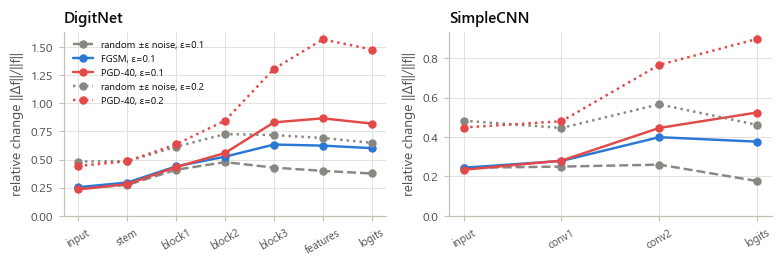

In [20]:
# Perturbation amplification: relative change of each layer's representation,
# ||f_l(x') - f_l(x)|| / ||f_l(x)||, for adversarial vs random sign noise of the same size.
@torch.no_grad()
def layer_reps(model, x):
    reps = {}
    logits, maps = model(x, return_maps=True)
    reps["input"] = x
    for k in maps:
        reps[k] = maps[k]
    reps["logits"] = logits
    return reps


def relative_change(model, x, x2):
    a, b = layer_reps(model, x), layer_reps(model, x2)
    return {k: ((b[k] - a[k]).flatten(1).norm(dim=1) / a[k].flatten(1).norm(dim=1).clamp_min(1e-9)).mean().item()
            for k in a}


xs_amp, ys_amp = x_test[:2000], y_test[:2000]
rows = []
for mname, m in [("DigitNet", digitnet), ("SimpleCNN", simplecnn)]:
    for eps in [0.1, 0.2]:
        seed_everything(0)
        for aname, xa_ in [("random ±ε noise", noise_attack(m, xs_amp, ys_amp, eps)),
                           ("FGSM", run_attack(m, fgsm, xs_amp, ys_amp, eps=eps)),
                           ("PGD-40", run_attack(m, pgd, xs_amp, ys_amp, eps=eps, steps=40))]:
            for layer, v in relative_change(m, xs_amp, xa_).items():
                rows.append({"model": mname, "eps": eps, "perturbation": aname, "layer": layer, "rel_change": v})
amp = pd.DataFrame(rows)
save_table(amp, "amplification")
SUMMARY["amplification"] = amp.to_dict(orient="records")
display(amp[amp.eps == 0.1].pivot_table(index=["model", "perturbation"], columns="layer", values="rel_change", sort=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
for ax, mname in zip(axes, ["DigitNet", "SimpleCNN"]):
    s = amp[(amp.model == mname)]
    layers = list(dict.fromkeys(s.layer))
    for (aname, eps), st in {("random ±ε noise", 0.1): dict(color=MUTED, ls="--"),
                             ("FGSM", 0.1): dict(color=PALETTE[0]), ("PGD-40", 0.1): dict(color=PALETTE[7]),
                             ("random ±ε noise", 0.2): dict(color=MUTED, ls=":"),
                             ("PGD-40", 0.2): dict(color=PALETTE[7], ls=":")}.items():
        v = s[(s.perturbation == aname) & (s.eps == eps)].set_index("layer").loc[layers, "rel_change"]
        ax.plot(range(len(layers)), v.values, marker="o", label=f"{aname}, ε={eps}", **st)
    ax.set_xticks(range(len(layers))); ax.set_xticklabels(layers, rotation=30, fontsize=7)
    ax.set_ylim(0, None); ax.set_title(mname); ax.set_ylabel("relative change ‖Δf‖/‖f‖")
axes[0].legend(fontsize=6.5)
fig.tight_layout()
save_fig(fig, "fig_amplification")
plt.show()

In [21]:
# Grad-CAM (Selvaraju et al., 2017) on block 3 and input-gradient saliency, clean vs adversarial
def gradcam(model, x, cls, layer="block3"):
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)   # weights are frozen, so the graph must start at the input
        logits, maps = model(x, return_maps=True)
        A = maps[layer]
        (g,) = torch.autograd.grad(logits.gather(1, cls[:, None]).sum(), A)
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * A).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    return (cam / cam.flatten(1).max(1).values.clamp_min(1e-12).view(-1, 1, 1, 1)).detach()


def saliency(model, x, cls):
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        (g,) = torch.autograd.grad(model(x).gather(1, cls[:, None]).sum(), x)
    s = g.abs()
    return (s / s.flatten(1).max(1).values.clamp_min(1e-12).view(-1, 1, 1, 1)).detach()

### 4.4 Black-box attacks: transferability and query-based SimBA

In [22]:
N_BB = 2000
xb_, yb_ = x_test[:N_BB], y_test[:N_BB]
SOURCES = {"DigitNet": digitnet, "DigitNet (seed 1)": digitnet_s1, "SimpleCNN": simplecnn, "TemplateDNN": template_dnn}
TARGETS = {"DigitNet": digitnet, "DigitNet (seed 1)": digitnet_s1, "SimpleCNN": simplecnn, "TemplateDNN": template_dnn}
transfer = {}
for aname, fn, kw in [("PGD-40", pgd, {"steps": 40}), ("MI-FGSM", mifgsm, {"steps": 10})]:
    mat = pd.DataFrame(index=list(SOURCES), columns=list(TARGETS), dtype=float)
    for sname, sm in SOURCES.items():
        seed_everything(0)
        xa_s = run_attack(sm, fn, xb_, yb_, eps=0.2, **kw)
        for tname, tm in TARGETS.items():
            mat.loc[sname, tname] = accuracy(tm, xa_s, yb_)
    transfer[aname] = mat
    save_table(mat, f"transfer_{aname}")
SUMMARY["transfer_eps0.2"] = {k: df_json(v) for k, v in transfer.items()}
for k, v in transfer.items():
    print(k); display((100 * v).round(1))

PGD-40


,DigitNet,DigitNet (seed 1),SimpleCNN,TemplateDNN
DigitNet,0.0,7.9,89.1,60.8
DigitNet (seed 1),7.3,0.0,91.0,65.8
SimpleCNN,26.9,18.9,0.1,47.2
TemplateDNN,56.9,30.5,93.6,0.0


MI-FGSM


,DigitNet,DigitNet (seed 1),SimpleCNN,TemplateDNN
DigitNet,2.1,12.3,80.3,48.2
DigitNet (seed 1),13.1,1.1,83.5,47.1
SimpleCNN,36.1,23.5,9.8,48.8
TemplateDNN,54.4,31.2,90.7,0.5


In [23]:
# SimBA (score-based black box) against the standard models, eps = 0.3, 1,000 test images
N_SB = 1000
simba_res = {}
rows = []
t0 = time.time()
for mname, m in STD_MODELS.items():
    for eps in [0.3]:
        seed_everything(0)
        xa_sb, q = simba(m, x_test[:N_SB], y_test[:N_SB], eps)
        q = q.cpu().numpy()
        ok = predict_logits(m, x_test[:N_SB]).argmax(1).cpu().numpy() == y_test_np[:N_SB]
        simba_res[(mname, eps)] = q[ok]
        rows.append({"model": mname, "eps": eps, "adv_acc": accuracy(m, xa_sb, y_test[:N_SB]),
                     "success_rate": np.isfinite(q[ok]).mean(),
                     "median queries (successes)": np.median(q[ok][np.isfinite(q[ok])]) if np.isfinite(q[ok]).any() else np.nan})
simba_df = pd.DataFrame(rows)
save_table(simba_df, "simba")
SUMMARY["simba"] = simba_df.to_dict(orient="records")
print(f"SimBA: {time.time() - t0:.0f}s")
display(simba_df)

SimBA: 41s


,model,eps,adv_acc,success_rate,median queries (successes)
0,DigitNet,0.3,0.339,0.6616,187.0
1,SimpleCNN,0.3,0.481,0.5156,340.5
2,TemplateDNN,0.3,0.142,0.8541,152.0


## 5. Defenses and robustness improvements
### 5.1 Adversarial training (robust optimization)

[cache] at_pgd_eps0.3_s0: best epoch 19, val clean 99.46%, val PGD 97.70%
[cache] at_fgsm_rs_eps0.3_s0: best epoch 7, val clean 98.80%, val PGD 53.90%


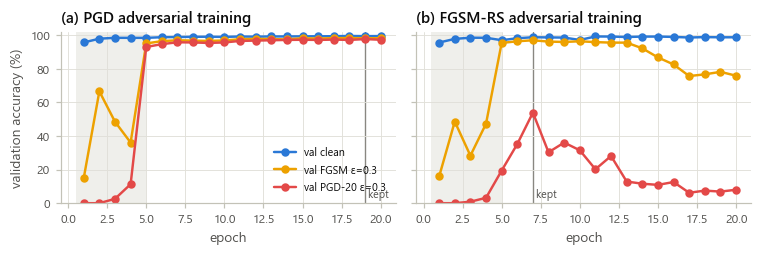

In [24]:
AT_PGD = ATConfig(method="pgd")
AT_FGSM = ATConfig(method="fgsm_rs")
at_pgd, rec_pgd = adversarial_train(AT_PGD)
at_fgsm, rec_fgsm = adversarial_train(AT_FGSM)
SUMMARY["at_runs"] = {r["name"]: {k: r[k] for k in ["best_epoch", "best_val_rob", "best_val_clean", "train_time_s"]}
                      for r in (rec_pgd, rec_fgsm)}
std_time = json.loads((CKPT_DIR / "module02" / "main_s0.json").read_text())["train_time_s"]
SUMMARY["std_train_time_s"] = std_time

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.4), sharey=True)
for ax, rec, title in [(axes[0], rec_pgd, "(a) PGD adversarial training"), (axes[1], rec_fgsm, "(b) FGSM-RS adversarial training")]:
    h = pd.DataFrame(rec["history"])
    ax.plot(h.epoch, 100 * h.val_clean_acc, marker="o", color=PALETTE[0], label="val clean")
    ax.plot(h.epoch, 100 * h.val_fgsm_acc, marker="o", color=PALETTE[3], label="val FGSM ε=0.3")
    ax.plot(h.epoch, 100 * h.val_pgd_acc, marker="o", color=PALETTE[7], label="val PGD-20 ε=0.3")
    ax.axvline(rec["best_epoch"], color=MUTED, lw=0.9, zorder=0)
    ax.text(rec["best_epoch"], 3, " kept", color=INK2, fontsize=7)
    ax.axvspan(0.5, rec["config"]["ramp_epochs"], color=GRID, alpha=0.5, lw=0)
    ax.set_title(title); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation accuracy (%)"); axes[0].set_ylim(0, 102)
axes[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig_at_training")
plt.show()

### 5.2 Input preprocessing defenses, attacked naively and adaptively (BPDA)

In [25]:
TRANSFORMS = {"bit depth 1": lambda x: bit_depth(x, 1), "median 3×3": lambda x: median_filter(x, 3),
              "Gaussian blur σ=1": lambda x: gaussian_blur(x, 1.0)}
xd, yd = x_test[:N_BB], y_test[:N_BB]
rows = []
for tname, tf in TRANSFORMS.items():
    defended = freeze(Preprocessed(digitnet, tf))
    adaptive = freeze(Preprocessed(digitnet, tf, bpda=True))
    row = {"defense": tname, "clean": accuracy(defended, xd, yd)}
    for eps in REPORT_EPS:
        seed_everything(0)
        # (i) oblivious attacker: crafts PGD on the undefended DigitNet, the defense filters the input
        row[f"oblivious {eps}"] = accuracy(defended, run_attack(digitnet, pgd, xd, yd, eps=eps, steps=40), yd)
        # (ii) naive white-box: PGD with gradients taken straight through the transform
        row[f"naive {eps}"] = accuracy(defended, run_attack(defended, pgd, xd, yd, eps=eps, steps=40), yd)
        # (iii) adaptive white-box: PGD with BPDA (identity backward), 100 steps
        row[f"BPDA {eps}"] = accuracy(defended, run_attack(adaptive, pgd, xd, yd, eps=eps, steps=100), yd)
    rows.append(row)
prep_df = pd.DataFrame(rows).set_index("defense")
save_table(prep_df, "preprocessing")
SUMMARY["preprocessing"] = df_json(prep_df)
display((100 * prep_df).round(1))

,clean,oblivious 0.1,naive 0.1,BPDA 0.1,oblivious 0.2,naive 0.2,BPDA 0.2,oblivious 0.3,naive 0.3,BPDA 0.3
defense,,,,,,,,,,
bit depth 1,99.2,97.9,99.3,97.1,95.7,99.1,91.3,95.5,99.0,75.5
median 3×3,99.0,34.8,18.5,24.2,3.4,0.4,1.0,1.2,0.0,0.0
Gaussian blur σ=1,98.4,56.0,16.8,28.0,18.5,1.2,3.3,8.2,0.0,0.1


### 5.3 Robustness of all defended models (full evaluation, incl. strong and black-box attacks)

In [26]:
DEFENDED = {"DigitNet (standard)": digitnet, "DigitNet + FGSM-RS AT": at_fgsm, "DigitNet + PGD AT": at_pgd,
            "DigitNet + bit depth 1 (BPDA)": None}
rows, curves = [], []
xe, ye = x_test, y_test
for mname, m in DEFENDED.items():
    if m is None:       # preprocessing defense: classify with the transform, attack through BPDA
        eval_m = freeze(Preprocessed(digitnet, TRANSFORMS["bit depth 1"]))
        att_m = freeze(Preprocessed(digitnet, TRANSFORMS["bit depth 1"], bpda=True))
    else:
        eval_m = att_m = m
    row = {"model": mname, "clean": accuracy(eval_m, xe, ye)}
    for eps in REPORT_EPS + [0.35, 0.4]:
        seed_everything(0)
        a_f = accuracy(eval_m, run_attack(att_m, fgsm, xe, ye, eps=eps), ye)
        a_p = accuracy(eval_m, run_attack(att_m, pgd, xe, ye, eps=eps, steps=40), ye)
        curves.append({"model": mname, "eps": eps, "FGSM": a_f, "PGD-40": a_p})
        if eps in REPORT_EPS:
            row[f"FGSM {eps}"], row[f"PGD-40 {eps}"] = a_f, a_p
    seed_everything(0)
    row["PGD-100×10 0.3 (2k)"] = accuracy(eval_m, run_attack(att_m, pgd, xe[:2000], ye[:2000], eps=0.3, steps=100,
                                                            restarts=10), ye[:2000])
    seed_everything(0)
    row["transfer 0.3 (from seed 1)"] = accuracy(eval_m, run_attack(digitnet_s1, pgd, xe, ye, eps=0.3, steps=40), ye)
    seed_everything(0)
    xa_sb, _ = simba(eval_m, xe[:N_SB], ye[:N_SB], 0.3)
    row["SimBA 0.3 (1k)"] = accuracy(eval_m, xa_sb, ye[:N_SB])
    rows.append(row)
defense_df = pd.DataFrame(rows).set_index("model")
curves_df = pd.DataFrame(curves)
save_table(defense_df, "defenses")
save_table(curves_df, "defense_curves")
SUMMARY["defenses"] = df_json(defense_df)
SUMMARY["defense_curves"] = curves_df.to_dict(orient="records")
display((100 * defense_df).round(2))

,clean,FGSM 0.1,PGD-40 0.1,FGSM 0.2,PGD-40 0.2,FGSM 0.3,PGD-40 0.3,PGD-100×10 0.3 (2k),transfer 0.3 (from seed 1),SimBA 0.3 (1k)
model,,,,,,,,,,
DigitNet (standard),99.70,71.35,11.96,17.19,0.00,10.86,0.00,0.00,4.49,33.9
DigitNet + FGSM-RS AT,99.20,98.08,97.75,96.92,94.04,96.73,51.39,33.70,98.49,36.9
DigitNet + PGD AT,99.49,98.99,98.95,98.60,98.26,98.16,97.31,95.30,99.14,95.1
DigitNet + bit depth 1 (BPDA),99.42,98.15,97.75,95.78,93.24,90.62,79.76,63.95,97.70,73.0


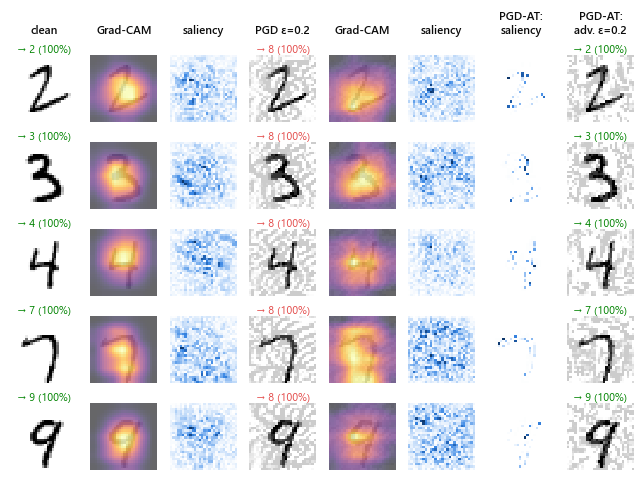

In [27]:
# Figure: Grad-CAM and saliency, standard vs PGD-trained DigitNet, clean vs adversarial (eps = 0.2)
ids = [int(np.flatnonzero((y_test_np == d) & (clean_pred == d))[2]) for d in [2, 3, 4, 7, 9]]
xg, yg = x_test[ids], y_test[ids]
fig, axes = plt.subplots(len(ids), 8, figsize=(7.4, 4.9))
col_titles = ["clean", "Grad-CAM", "saliency", "PGD ε=0.2", "Grad-CAM", "saliency", "PGD-AT:\nsaliency", "PGD-AT:\nadv. ε=0.2"]
seed_everything(0)
xg_adv = pgd(digitnet, xg, yg, 0.2, steps=40)
xg_adv_rob = pgd(at_pgd, xg, yg, 0.2, steps=40)
kc, cc = pred_title(digitnet, xg)
ka, ca = pred_title(digitnet, xg_adv)
kr, cr = pred_title(at_pgd, xg_adv_rob)
cam_c = gradcam(digitnet, xg, torch.as_tensor(kc, device=DEVICE))
cam_a = gradcam(digitnet, xg_adv, torch.as_tensor(ka, device=DEVICE))
sal_c = saliency(digitnet, xg, yg)
sal_a = saliency(digitnet, xg_adv, torch.as_tensor(ka, device=DEVICE))
sal_r = saliency(at_pgd, xg, yg)
for r in range(len(ids)):
    show_img(axes[r, 0], xg[r, 0], title=f"→ {kc[r]} ({100 * cc[r]:.0f}%)", color=GOOD)
    show_img(axes[r, 1], xg[r, 0], cmap="gray_r", alpha=0.35); axes[r, 1].imshow(cam_c[r, 0].cpu(), cmap="inferno", alpha=0.6)
    show_img(axes[r, 2], sal_c[r, 0], cmap=seq_cmap())
    show_img(axes[r, 3], xg_adv[r, 0], title=f"→ {ka[r]} ({100 * ca[r]:.0f}%)", color=BAD if ka[r] != yg[r].item() else GOOD)
    show_img(axes[r, 4], xg_adv[r, 0], cmap="gray_r", alpha=0.35); axes[r, 4].imshow(cam_a[r, 0].cpu(), cmap="inferno", alpha=0.6)
    show_img(axes[r, 5], sal_a[r, 0], cmap=seq_cmap())
    show_img(axes[r, 6], sal_r[r, 0], cmap=seq_cmap())
    show_img(axes[r, 7], xg_adv_rob[r, 0], title=f"→ {kr[r]} ({100 * cr[r]:.0f}%)",
             color=GOOD if kr[r] == yg[r].item() else BAD)
fig.subplots_adjust(wspace=0.06, hspace=0.3, top=0.88)
for j, t in enumerate(col_titles):          # column headers above the first row's prediction titles
    b = axes[0, j].get_position()
    fig.text((b.x0 + b.x1) / 2, b.y1 + 0.035, t, ha="center", va="bottom", fontsize=7.5,
             fontweight="semibold", color=INK)
save_fig(fig, "fig_gradcam")
plt.show()

## 6. Summary

In [28]:
def to_jsonable(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


(RESULTS_DIR / "summary.json").write_text(json.dumps(SUMMARY, indent=1, default=to_jsonable))
d0 = defense_df.loc["DigitNet (standard)"]
d1 = defense_df.loc["DigitNet + PGD AT"]
print(f"DigitNet clean {100 * d0['clean']:.2f}% | FGSM 0.1 {100 * d0['FGSM 0.1']:.2f}% | PGD 0.1 {100 * d0['PGD-40 0.1']:.2f}% "
      f"| PGD 0.3 {100 * d0['PGD-40 0.3']:.2f}%")
print(f"PGD-AT   clean {100 * d1['clean']:.2f}% | FGSM 0.3 {100 * d1['FGSM 0.3']:.2f}% | PGD 0.3 {100 * d1['PGD-40 0.3']:.2f}% "
      f"| PGD-100x10 0.3 {100 * d1['PGD-100×10 0.3 (2k)']:.2f}%")

DigitNet clean 99.70% | FGSM 0.1 71.35% | PGD 0.1 11.96% | PGD 0.3 0.00%
PGD-AT   clean 99.49% | FGSM 0.3 98.16% | PGD 0.3 97.31% | PGD-100x10 0.3 95.30%
